In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv('/content/netflix_titles.csv')
print("Dataset successfully loaded!")

Dataset successfully loaded!


Basic Exploration

In [ ]:
df.head() #for first 5 rows

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:
df.shape # for no of (rows,columns)

(8807, 12)

In [ ]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

In [ ]:
df.info() #for basic info of dataset

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [ ]:
df.isnull().sum() # for  check missing values of dataset

,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


In [ ]:
df.describe() # for statistical summary

,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


DATA CLEANING

In [ ]:
df.duplicated().sum()
df=df.drop_duplicates()
# for find and remove duplicates

In [ ]:
cols=['director','cast','country','date_added','rating','duration']
df[cols]=df[cols].fillna('Unknown') # for fill missing values

In [ ]:
df['date_added']=pd.to_datetime(
    df['date_added'],
    errors='coerce'
) # convert date columns

In [ ]:
df['date_added'].head() # for check it

,date_added
0,2021-09-25
1,2021-09-24
2,2021-09-24
3,2021-09-24
4,2021-09-24


In [ ]:
text_cols=['type','title','director','country','rating','duration'] # for remove extra spaces
for col in text_cols:
  df[col]=df[col].astype(str).str.strip()

In [ ]:
# Check data after cleaning
print("Dataset shape after cleaning:",df.shape)
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape after cleaning: (8807, 12)

Missing values:
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      98
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64


Cleaned Dataset

In [ ]:
df.to_csv('/content/netflix_titles_cleaned.csv',index=False)

In [ ]:
df_cleaned = pd.read_csv('/content/netflix_titles_cleaned.csv')
df_cleaned.head() # for check new cleaned file

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...



Exploratory Data Analysis



In [ ]:
df['type'].value_counts() # for find total no of movies and tv show

,count
type,
Movie,6131
TV Show,2676


<Axes: title={'center': 'Movies vs TV Shows'}, xlabel='type'>

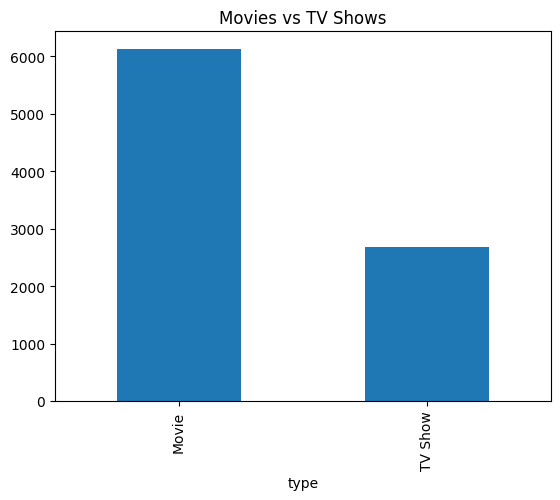

In [ ]:
df['type'].value_counts().plot(kind='bar',title='Movies vs TV Shows') # for plot his graph

In [ ]:
df['release_year'].value_counts() # for find maximun release year

,count
release_year,
2018,1147
2017,1032
2019,1030
2020,953
2016,902
...,...
1961,1
1925,1
1959,1


<Axes: title={'center': 'Top 10 Release Years'}, xlabel='release_year'>

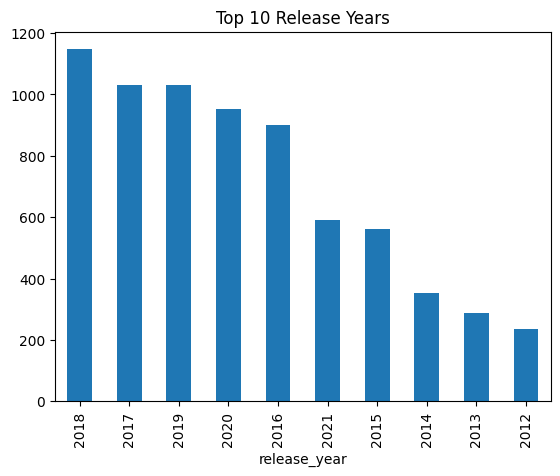

In [ ]:
df['release_year'].value_counts().head(10).plot(
    kind='bar',
    title='Top 10 Release Years'
)# for plot his graph

In [ ]:
df['rating'].value_counts().head(10) # for find top 10 rating content

,count
rating,
TV-MA,3207
TV-14,2160
TV-PG,863
R,799
PG-13,490
TV-Y7,334
TV-Y,307
PG,287
TV-G,220


<Axes: title={'center': 'Top 10 Ratings'}, xlabel='rating'>

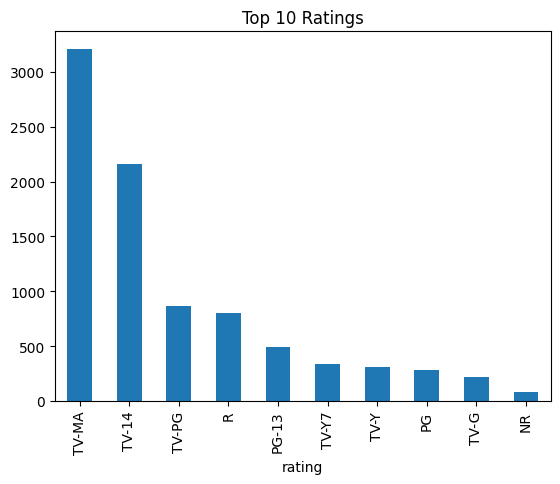

In [ ]:
df['rating'].value_counts().head(10).plot(
    kind='bar',
    title='Top 10 Ratings'
)

In [ ]:
df['country'].value_counts().head(10) # for find top 10 countries

,count
country,
United States,2818
India,972
United Kingdom,419
Japan,245
South Korea,199
Canada,181
Spain,145
France,124
Mexico,110


<Axes: title={'center': 'Top 10 Countries'}, xlabel='country'>

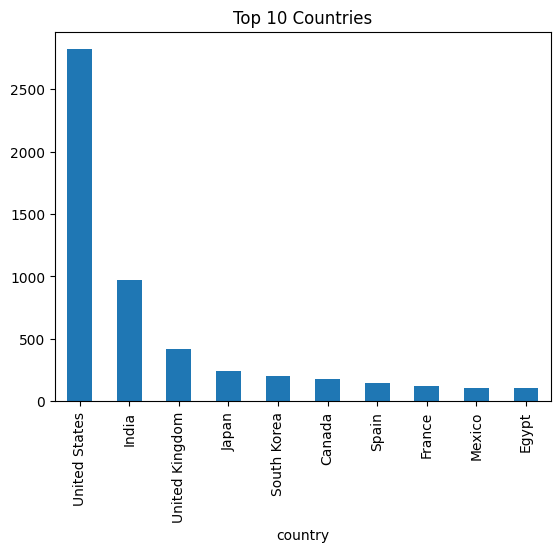

In [ ]:
df['country'].value_counts().head(10).plot(
    kind='bar',
    title='Top 10 Countries'
)

In [ ]:
df['listed_in'].value_counts().head(10) # for find most common categories

,count
listed_in,
"Dramas, International Movies",362
Documentaries,359
Stand-Up Comedy,334
"Comedies, Dramas, International Movies",274
"Dramas, Independent Movies, International Movies",252
Kids' TV,220
Children & Family Movies,215
"Children & Family Movies, Comedies",201
"Documentaries, International Movies",186


<Axes: title={'center': 'Movies vs TV Shows'}, ylabel='count'>

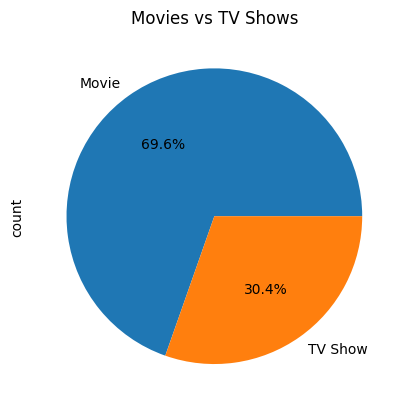

In [ ]:
df['type'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    title='Movies vs TV Shows'
)# for find movies vs tv shows